<a href="https://colab.research.google.com/github/nehasingh913833-gif/Parametric-and-Non-parametric-Brain-Function-Connectivity-Approach-for-Predicting-Autism./blob/main/1d_0l.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Environment Ready. Starting ABIDE Pipeline (Pearson + 1D CNN only)...
Loaded 1000 subjects. ASD (1): 488, Control (0): 512
Computing Parametric: Pearson Correlation...

Starting 5-Fold Cross-Validation for 1D CNN...
Training Fold 1/5...
Training Fold 2/5...
Training Fold 3/5...


Training Fold 4/5...


Training Fold 5/5...

=== FINAL RESULTS ===


,Approach,Connectome,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Parametric,Pearson,1D CNN,0.517,0.5074,0.3525,0.416,0.5179


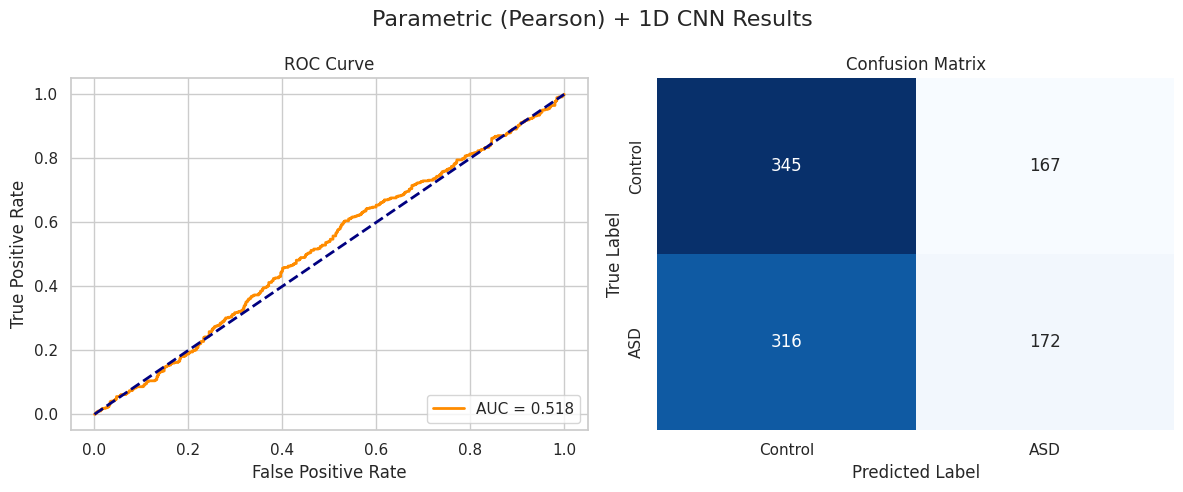

In [ ]:
# ==========================================
# STEP 1: CLEAN INSTALLATION OF DEPENDENCIES
# ==========================================
!pip install -q nilearn==0.13.0 scikit-learn seaborn matplotlib

import warnings
warnings.filterwarnings('ignore')
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nilearn.datasets import fetch_abide_pcp
from nilearn.connectome import ConnectivityMeasure

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
)

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print("\nEnvironment Ready. Starting ABIDE Pipeline (Pearson + 1D CNN only)...")

# ==========================================
# STEP 2: FETCH DATASET (SILENTLY) & CLEAN
# ==========================================
N_SAMPLES = 1000

print(f"Downloading {N_SAMPLES} pre-extracted ABIDE subjects (takes ~2 mins)...")
abide = fetch_abide_pcp(
    n_subjects=N_SAMPLES,
    pipeline='cpac',
    band_pass_filtering=True,
    global_signal_regression=False,
    derivatives=['rois_aal'], # Using 116 AAL ROIs to fit in Colab RAM/Disk
    quality_checked=False,
    verbose=0
)

# Extract Time Series & Labels
raw_time_series = abide.rois_aal[:N_SAMPLES]
y = (np.asarray(abide.phenotypic['DX_GROUP'])[:N_SAMPLES] == 1).astype(np.int32)

# Jitter zero-variance columns to prevent NaN matrices
time_series_list = []
rng = np.random.default_rng(42)
for ts in raw_time_series:
    ts = np.asarray(ts, dtype=np.float32)
    zero_std_cols = np.std(ts, axis=0) < 1e-8
    if np.any(zero_std_cols):
        ts[:, zero_std_cols] += rng.normal(0, 1e-5, size=(ts.shape[0], np.sum(zero_std_cols)))
    time_series_list.append(ts)

print(f"Loaded {len(time_series_list)} subjects. ASD (1): {np.sum(y==1)}, Control (0): {np.sum(y==0)}")

# ==========================================
# STEP 3: COMPUTE PARAMETRIC (PEARSON) CONNECTIVITY
# ==========================================
print("Computing Parametric: Pearson Correlation...")
pearson_matrices = np.nan_to_num(ConnectivityMeasure(kind='correlation').fit_transform(time_series_list), nan=0.0)

# Extract non-redundant upper triangle using NumPy (Flattening for 1D CNN)
triu_idx = np.triu_indices(pearson_matrices.shape[1], k=1)
X_flat = StandardScaler().fit_transform(pearson_matrices[:, triu_idx[0], triu_idx[1]])[..., np.newaxis]

# Clean up memory
del raw_time_series, time_series_list, pearson_matrices
gc.collect()

# ==========================================
# STEP 4: DEFINE 1D CNN & EVALUATOR
# ==========================================
def build_1d_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(16, 5, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

print("\nStarting 5-Fold Cross-Validation for 1D CNN...")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
all_y_true, all_y_prob, all_y_pred = [], [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_flat, y), 1):
    print(f"Training Fold {fold}/5...")
    X_train, X_val = X_flat[train_idx], X_flat[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    model = build_1d_cnn(X_flat.shape[1:])
    early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32, verbose=0, callbacks=[early_stop])

    y_prob = model.predict(X_val, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    all_y_true.extend(y_val)
    all_y_prob.extend(y_prob)
    all_y_pred.extend(y_pred)

# ==========================================
# STEP 5: RESULTS & VISUALIZATIONS
# ==========================================
cm = confusion_matrix(all_y_true, all_y_pred)
metrics = {
    'Approach': 'Parametric',
    'Connectome': 'Pearson',
    'Model': '1D CNN',
    'Accuracy': accuracy_score(all_y_true, all_y_pred),
    'Precision': precision_score(all_y_true, all_y_pred, zero_division=0),
    'Recall': recall_score(all_y_true, all_y_pred, zero_division=0),
    'F1-Score': f1_score(all_y_true, all_y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(all_y_true, all_y_prob)
}

print("\n=== FINAL RESULTS ===")
display(pd.DataFrame([metrics]).round(4))

# Plot ROC & CM side-by-side
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Parametric (Pearson) + 1D CNN Results", fontsize=16)

# ROC Curve
fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'])
axes[1].set_title("Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()